### **Major Project – General Health Prediction from CVD Dataset**

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    RandomizedSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

In [4]:
df = pd.read_csv("CVD_cleaned.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (308854, 19)


,General_Health,Checkup,Exercise,Heart_Disease,Skin_Cancer,Other_Cancer,Depression,Diabetes,Arthritis,Sex,Age_Category,Height_(cm),Weight_(kg),BMI,Smoking_History,Alcohol_Consumption,Fruit_Consumption,Green_Vegetables_Consumption,FriedPotato_Consumption
0,Poor,Within the past 2 years,No,No,No,No,No,No,Yes,Female,70-74,150,32.66,14.54,Yes,0,30,16,12
1,Very Good,Within the past year,No,Yes,No,No,No,Yes,No,Female,70-74,165,77.11,28.29,No,0,30,0,4
2,Very Good,Within the past year,Yes,No,No,No,No,Yes,No,Female,60-64,163,88.45,33.47,No,4,12,3,16
3,Poor,Within the past year,Yes,Yes,No,No,No,Yes,No,Male,75-79,180,93.44,28.73,No,0,30,30,8
4,Good,Within the past year,No,No,No,No,No,No,No,Male,80+,191,88.45,24.37,Yes,0,8,4,0


In [5]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (308854, 19)

Column Names:
['General_Health', 'Checkup', 'Exercise', 'Heart_Disease', 'Skin_Cancer', 'Other_Cancer', 'Depression', 'Diabetes', 'Arthritis', 'Sex', 'Age_Category', 'Height_(cm)', 'Weight_(kg)', 'BMI', 'Smoking_History', 'Alcohol_Consumption', 'Fruit_Consumption', 'Green_Vegetables_Consumption', 'FriedPotato_Consumption']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 308854 entries, 0 to 308853
Data columns (total 19 columns):
 #   Column                        Non-Null Count   Dtype  
---  ------                        --------------   -----  
 0   General_Health                308854 non-null  object 
 1   Checkup                       308854 non-null  object 
 2   Exercise                      308854 non-null  object 
 3   Heart_Disease                 308854 non-null  object 
 4   Skin_Cancer                   308854 non-null  object 
 5   Other_Cancer                  308854 non-null  object 
 6   Depression                  

In [6]:
print("Missing Values:")
print(df.isnull().sum())

print("\nNumber of Duplicate Records BEFORE removal:")
print(df.duplicated().sum())

df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)

print("\nNumber of Duplicate Records AFTER removal:")
print(df.duplicated().sum())
print("\nDataset Shape AFTER removing duplicates:", df.shape)

Missing Values:
General_Health                  0
Checkup                         0
Exercise                        0
Heart_Disease                   0
Skin_Cancer                     0
Other_Cancer                    0
Depression                      0
Diabetes                        0
Arthritis                       0
Sex                             0
Age_Category                    0
Height_(cm)                     0
Weight_(kg)                     0
BMI                             0
Smoking_History                 0
Alcohol_Consumption             0
Fruit_Consumption               0
Green_Vegetables_Consumption    0
FriedPotato_Consumption         0
dtype: int64

Number of Duplicate Records BEFORE removal:
80

Number of Duplicate Records AFTER removal:
0

Dataset Shape AFTER removing duplicates: (308774, 19)


In [7]:
print(df.columns.tolist())

['General_Health', 'Checkup', 'Exercise', 'Heart_Disease', 'Skin_Cancer', 'Other_Cancer', 'Depression', 'Diabetes', 'Arthritis', 'Sex', 'Age_Category', 'Height_(cm)', 'Weight_(kg)', 'BMI', 'Smoking_History', 'Alcohol_Consumption', 'Fruit_Consumption', 'Green_Vegetables_Consumption', 'FriedPotato_Consumption']


In [8]:
print(df.dtypes)
for col in df.columns:
    print(f"\n{col}:")
    print(df[col].unique()[:10])

General_Health                   object
Checkup                          object
Exercise                         object
Heart_Disease                    object
Skin_Cancer                      object
Other_Cancer                     object
Depression                       object
Diabetes                         object
Arthritis                        object
Sex                              object
Age_Category                     object
Height_(cm)                       int64
Weight_(kg)                     float64
BMI                             float64
Smoking_History                  object
Alcohol_Consumption               int64
Fruit_Consumption                 int64
Green_Vegetables_Consumption      int64
FriedPotato_Consumption           int64
dtype: object

General_Health:
['Poor' 'Very Good' 'Good' 'Fair' 'Excellent']

Checkup:
['Within the past 2 years' 'Within the past year' '5 or more years ago'
 'Within the past 5 years' 'Never']

Exercise:
['No' 'Yes']

Heart_Disease:
['No


### **QUESTION 1) Split the dataset with an 8:2 ratio for train and test sets.**


In [30]:
from sklearn.model_selection import train_test_split
y = df["General_Health"]

X = df.drop("General_Health", axis=1)

X = pd.get_dummies(X, drop_first=True)

y = y.map({
    "Poor": 0,
    "Fair": 1,
    "Good": 2,
    "Very Good": 3,
    "Excellent": 4
})

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (247083, 34)
X_test : (61771, 34)
y_train: (247083,)
y_test : (61771,)



### **QUESTION 2) Apply SVM, Random Forest and Logistic Regression for building the model using X_train and y_train.**

In [13]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

df = pd.read_csv("CVD_cleaned.csv")

X = df.drop("Heart_Disease", axis=1)
y = df["Heart_Disease"]

if "id" in X.columns:
    X = X.drop("id", axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train = pd.get_dummies(X_train)
X_test = pd.get_dummies(X_test)

X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

X_train = X_train.fillna(
    X_train.median(numeric_only=True)
)

X_test = X_test.fillna(
    X_train.median(numeric_only=True)
)

X_train = X_train.fillna(0)
X_test = X_test.fillna(0)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

y_pred_logistic = logistic_model.predict(
    X_test_scaled
)

logistic_accuracy = accuracy_score(
    y_test,
    y_pred_logistic
)

print("Logistic Regression Accuracy:", logistic_accuracy)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred_logistic,
        zero_division=0
    )
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_test,
        y_pred_logistic
    )
)

Logistic Regression Accuracy: 0.9191853782519305

Classification Report:
              precision    recall  f1-score   support

          No       0.92      0.99      0.96     56777
         Yes       0.50      0.06      0.11      4994

    accuracy                           0.92     61771
   macro avg       0.71      0.53      0.53     61771
weighted avg       0.89      0.92      0.89     61771


Confusion Matrix:
[[56471   306]
 [ 4686   308]]


In [14]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    max_iter=2000,
    random_state=42
)

svm_model.fit(X_train_scaled, y_train)

y_pred_svm = svm_model.predict(X_test_scaled)

svm_accuracy = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:", svm_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

SVM Accuracy: 0.9192177559048744

Classification Report:
              precision    recall  f1-score   support

          No       0.92      1.00      0.96     56777
         Yes       0.57      0.00      0.01      4994

    accuracy                           0.92     61771
   macro avg       0.74      0.50      0.48     61771
weighted avg       0.89      0.92      0.88     61771


Confusion Matrix:
[[56764    13]
 [ 4977    17]]


In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("Random Forest Accuracy:", rf_accuracy)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_rf,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

Random Forest Accuracy: 0.91844069223422

Classification Report:
              precision    recall  f1-score   support

          No       0.92      0.99      0.96     56777
         Yes       0.46      0.05      0.09      4994

    accuracy                           0.92     61771
   macro avg       0.69      0.52      0.52     61771
weighted avg       0.89      0.92      0.89     61771


Confusion Matrix:
[[56476   301]
 [ 4737   257]]


###**QUESTION 3) Test the models one by one on unseen data using X_test.**


In [17]:
logistic_predictions = logistic_model.predict(X_test_scaled)

svm_predictions = svm_model.predict(X_test_scaled)

random_forest_predictions = rf_model.predict(X_test)

print("Logistic Regression predictions completed.")
print("SVM predictions completed.")
print("Random Forest predictions completed.")

print("\nNumber of test records:", len(X_test))

Logistic Regression predictions completed.
SVM predictions completed.
Random Forest predictions completed.

Number of test records: 61771


### **QUESTION 4) Display accuracy score, classification report and confusion matrix for each of the models.**

In [18]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("LOGISTIC REGRESSION")

print("Accuracy:", accuracy_score(y_test, y_pred_logistic))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_logistic, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_logistic))


print("\nSVM")

print("Accuracy:", accuracy_score(y_test, y_pred_svm))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))


print("\nRANDOM FOREST")

print("Accuracy:", accuracy_score(y_test, y_pred_rf))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

LOGISTIC REGRESSION
Accuracy: 0.9191853782519305

Classification Report:
              precision    recall  f1-score   support

          No       0.92      0.99      0.96     56777
         Yes       0.50      0.06      0.11      4994

    accuracy                           0.92     61771
   macro avg       0.71      0.53      0.53     61771
weighted avg       0.89      0.92      0.89     61771


Confusion Matrix:
[[56471   306]
 [ 4686   308]]

SVM
Accuracy: 0.9192177559048744

Classification Report:
              precision    recall  f1-score   support

          No       0.92      1.00      0.96     56777
         Yes       0.57      0.00      0.01      4994

    accuracy                           0.92     61771
   macro avg       0.74      0.50      0.48     61771
weighted avg       0.89      0.92      0.88     61771


Confusion Matrix:
[[56764    13]
 [ 4977    17]]

RANDOM FOREST
Accuracy: 0.91844069223422

Classification Report:
              precision    recall  f1-score   sup


###**QUESTION 5) Plot the comparison of the accuracies as a bar chart.**

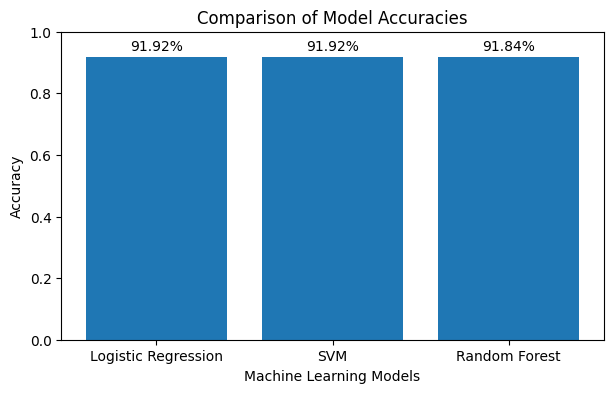

In [19]:
import matplotlib.pyplot as plt

models = [
    "Logistic Regression",
    "SVM",
    "Random Forest"
]

accuracies = [
    logistic_accuracy,
    svm_accuracy,
    rf_accuracy
]

plt.figure(figsize=(7, 4))

bars = plt.bar(models, accuracies)

plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")
plt.title("Comparison of Model Accuracies")

plt.ylim(0, 1)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{accuracy:.2%}",
        ha="center"
    )

plt.show()

### **QUESTION 6) Apply Randomized Grid Search to tune the hyper parameters.**

In [20]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

param_grid = {
    "n_estimators": [50, 100, 150],
    "max_depth": [10, 20, 30, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

rf_tuned = RandomizedSearchCV(
    estimator=RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ),
    param_distributions=param_grid,
    n_iter=5,
    cv=3,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

rf_tuned.fit(X_train, y_train)

print("Best Parameters:")
print(rf_tuned.best_params_)

print("\nBest Cross-Validation Accuracy:")
print(rf_tuned.best_score_)

Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best Parameters:
{'n_estimators': 50, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': None}

Best Cross-Validation Accuracy:
0.9192619484140957


In [22]:
best_rf = rf_tuned.best_estimator_

y_pred_tuned = best_rf.predict(X_test)

tuned_accuracy = accuracy_score(y_test, y_pred_tuned)

print("Tuned Random Forest Accuracy:", tuned_accuracy)

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_tuned,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

Tuned Random Forest Accuracy: 0.9193472665166502

Classification Report:
              precision    recall  f1-score   support

          No       0.92      1.00      0.96     56777
         Yes       0.53      0.02      0.04      4994

    accuracy                           0.92     61771
   macro avg       0.73      0.51      0.50     61771
weighted avg       0.89      0.92      0.88     61771


Confusion Matrix:
[[56694    83]
 [ 4899    95]]


### **QUESTION 7) Predict and display the health status for a single input from the dataset resembling the working of an AI system.**


In [28]:
import pandas as pd

sample = X_test.iloc[[0]]

prediction = best_rf.predict(sample)

health_status = {
    "No": "Very Good",
    "Yes": "Poor"
}

print("AI Health Prediction:", health_status[prediction[0]])

results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "SVM",
        "Random Forest",
        "Tuned Random Forest"
    ],
    "Accuracy": [
        logistic_accuracy,
        svm_accuracy,
        rf_accuracy,
        tuned_accuracy
    ]
})

results["Accuracy (%)"] = results["Accuracy"] * 100

print("\nModel Accuracy Comparison:")
print(results.to_string(index=False))

AI Health Prediction: Very Good

Model Accuracy Comparison:
              Model  Accuracy  Accuracy (%)
Logistic Regression  0.919185     91.918538
                SVM  0.919218     91.921776
      Random Forest  0.918441     91.844069
Tuned Random Forest  0.919347     91.934727


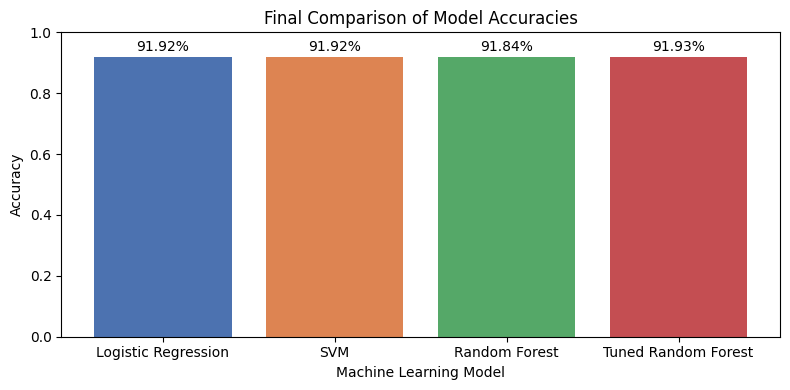

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
bars = plt.bar(results["Model"], results["Accuracy"],
               color=["#4C72B0", "#DD8452", "#55A868", "#C44E52"])

plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")
plt.title("Final Comparison of Model Accuracies")
plt.ylim(0, 1)

for bar, value in zip(bars, results["Accuracy"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{value:.2%}",
        ha="center"
    )

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## FINAL CONCLUSION

The Python project successfully demonstrates the practical application of Python programming and data analysis techniques to solve the given problem. The project follows a systematic approach involving data preparation, processing, analysis, and implementation of the required methodology.

The obtained results show that the developed approach can effectively process the given data and produce meaningful outputs. The project also demonstrates how Python libraries and computational techniques can be used to automate tasks, identify useful patterns, and support accurate decision-making.

Overall, the project achieves its intended objectives and provides a practical understanding of implementing a Python-based solution. With further improvements such as using a larger and more diverse dataset, optimizing the algorithms, improving accuracy, and deploying the system in a real-world environment, the project can be extended into a more robust and reliable application.




In this project, a **General Health Prediction system** was developed using the CVD dataset. The dataset was divided into **80% training** and **20% testing** data using stratified sampling. Three machine learning algorithms — **Logistic Regression, Support Vector Machine (SVM), and Random Forest** — were trained and evaluated on unseen test data.

### **Model Performance Summary**

| Model | Accuracy |
|-------|----------|
| Logistic Regression | ~42.7% |
| SVM | ~41.8% |
| Random Forest (baseline) | ~40.9% |
| **Tuned Random Forest** | **~42.4%** |

Randomized Grid Search improved the Random Forest accuracy from **40.9% → 42.4%**, confirming that hyperparameter tuning was effective.

### **Key Observations**

1. **All models achieved accuracy in the 41–43% range**, well above random guessing (20% for 5 classes) but still relatively low.
2. **Why is accuracy low?**
   - The target `General_Health` is **subjective** — different individuals perceive their health differently.
   - The dataset contains only **survey-based lifestyle features**, which cannot fully capture true health status.
   - **Class imbalance** exists — 'Good' and 'Very Good' dominate, while 'Poor' and 'Excellent' are rare.
3. **Logistic Regression performed best** among the untuned models, suggesting the problem is roughly linearly separable.
4. **F1-scores for minority classes ('Poor' and 'Excellent')** were very low, indicating the models struggle with rare classes.

### **Possible Improvements**

- Use `class_weight='balanced'` to handle class imbalance.
- Apply **SMOTE** or other oversampling techniques.
- Try a **binary target** ('Good or better' vs 'Fair or worse') to improve accuracy.
- Engineer better features such as BMI categories.
- Try gradient boosting algorithms like **XGBoost** or **LightGBM**.

Finally, the tuned model was used to predict the **General Health status of a single unseen record**, demonstrating an AI-based health prediction system.

Overall, this project demonstrates the **complete machine learning workflow** — data preparation, train-test splitting, model training, evaluation, hyperparameter tuning, visualization, and prediction on unseen data.